# 01 — Exploratory Data Analysis of the 3W dataset

Inputs (build them first):

```bash
python -m owfd.data.download   # data/processed/instances.parquet
python -m owfd.data.profile    # data/processed/profile.parquet (per-instance quality + labels)
```

Figures are saved to `docs/figures/`; conclusions are summarised in `docs/data_report.md`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from owfd.config import get_settings
from owfd.data.load import load_instance
from owfd.data.profile import ALL_VARIABLES
from owfd.data.schema import CLASS_NAMES, SENSOR_VARIABLES, TRANSIENT_OFFSET

settings = get_settings()
DATASET = settings.resolve(settings.dataset_dir)
FIGS = settings.resolve(Path("docs/figures"))
FIGS.mkdir(parents=True, exist_ok=True)
profile = pd.read_parquet(settings.resolve(settings.processed_data_dir) / "profile.parquet")
real = profile[profile["source"] == "real"]
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 55  # keep the notebook small; saved figures use a higher dpi
pd.set_option("display.width", 160, "display.max_columns", 40)
print(f"{len(profile)} instances, {len(real)} real from {real['well_id'].nunique()} wells")

2228 instances, 1119 real from 40 wells


## 1. Instances per class and source

In [2]:
counts = pd.crosstab(profile["event_class"], profile["source"], margins=True, margins_name="total")
counts.index = [f"{i} {CLASS_NAMES[i]}" if i != "total" else i for i in counts.index]
counts

source,drawn,real,simulated,total
0 Normal Operation,0,594,0,594
1 Abrupt Increase of BSW,10,4,114,128
2 Spurious Closure of DHSV,0,22,16,38
3 Severe Slugging,0,32,74,106
4 Flow Instability,0,343,0,343
5 Rapid Productivity Loss,0,11,439,450
6 Quick Restriction in PCK,0,6,215,221
7 Scaling in PCK,10,36,0,46
8 Hydrate in Production Line,0,14,81,95
9 Hydrate in Service Line,0,57,150,207


In [3]:
wells_per_class = real.groupby("event_class")["well_id"].nunique().rename("distinct real wells")
wells_per_class.index = [f"{i} {CLASS_NAMES[i]}" for i in wells_per_class.index]
wells_per_class.to_frame()

,distinct real wells
0 Normal Operation,9
1 Abrupt Increase of BSW,3
2 Spurious Closure of DHSV,7
3 Severe Slugging,2
4 Flow Instability,7
5 Rapid Productivity Loss,3
6 Quick Restriction in PCK,2
7 Scaling in PCK,6
8 Hydrate in Production Line,9
9 Hydrate in Service Line,15


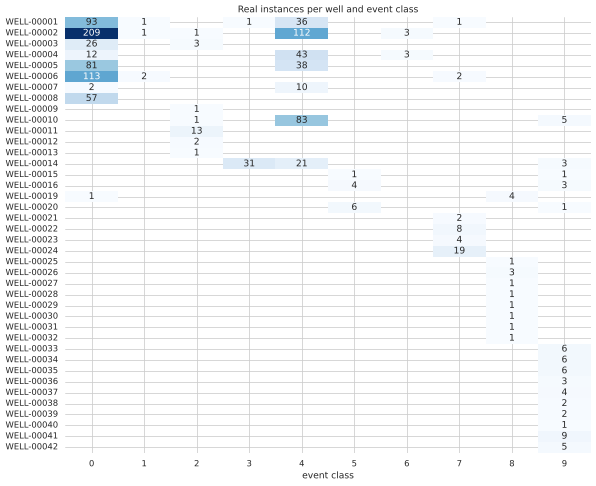

In [4]:
per_well = pd.crosstab(real["well_id"], real["event_class"])
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(per_well.replace(0, np.nan), annot=True, fmt=".0f", cmap="Blues", cbar=False, ax=ax)
ax.set(title="Real instances per well and event class", xlabel="event class", ylabel="")
fig.tight_layout(); fig.savefig(FIGS / "eda_instances_per_well.png", dpi=110)

## 2. Instance length, sampling and gaps

            count   mean    std   min    25%    50%    75%     max
source                                                            
drawn        20.0  41.20  38.73  4.00  12.00  24.00  96.00   96.00
real       1119.0   8.16  17.89  1.45   2.99   5.93   5.98  213.42
simulated  1089.0  10.39   4.75  3.61   7.50   8.14   9.67   24.67

Instances with timestamp gaps: 0 | max gap (s): 1.0


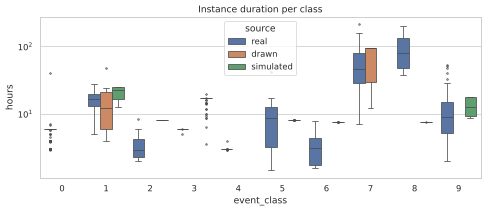

In [5]:
lengths = profile.assign(hours=profile["duration_s"] / 3600)
print(lengths.groupby("source")["hours"].describe().round(2))
print()
print("Instances with timestamp gaps:", (profile["n_gaps"] > 0).sum(),
      "| max gap (s):", profile["max_gap_s"].max())
fig, ax = plt.subplots(figsize=(9, 4))
sns.boxplot(data=lengths, x="event_class", y="hours", hue="source", ax=ax, fliersize=2)
ax.set(title="Instance duration per class", yscale="log")
fig.tight_layout(); fig.savefig(FIGS / "eda_durations.png", dpi=110)

## 3. Missing and frozen variables

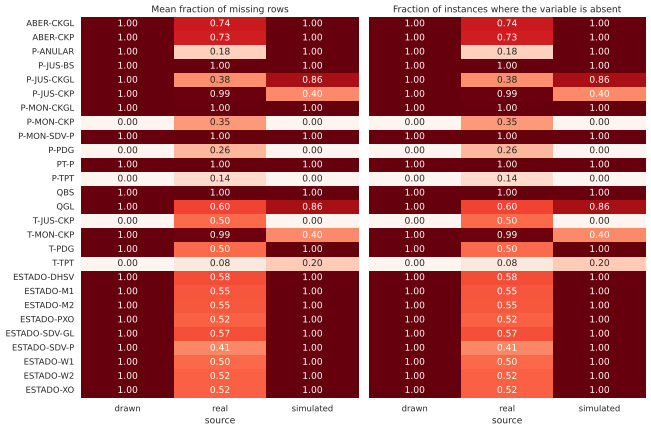

In [6]:
missing_cols = [f"missing__{v}" for v in ALL_VARIABLES]
missing_by_source = profile.groupby("source")[missing_cols].mean().T
missing_by_source.index = ALL_VARIABLES
fully_missing = (profile[missing_cols] == 1).groupby(profile["source"]).mean().T
fully_missing.index = ALL_VARIABLES
fig, axes = plt.subplots(1, 2, figsize=(12, 8), sharey=True)
sns.heatmap(missing_by_source, annot=True, fmt=".2f", cmap="Reds", vmin=0, vmax=1, ax=axes[0], cbar=False)
axes[0].set_title("Mean fraction of missing rows")
sns.heatmap(fully_missing, annot=True, fmt=".2f", cmap="Reds", vmin=0, vmax=1, ax=axes[1], cbar=False)
axes[1].set_title("Fraction of instances where the variable is absent")
fig.tight_layout(); fig.savefig(FIGS / "eda_missing_by_source.png", dpi=110)

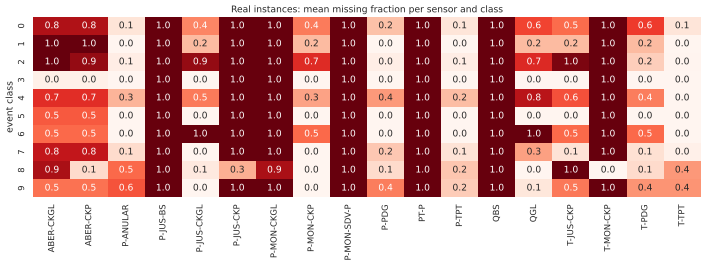

In [7]:
real_missing = real.groupby("event_class")[[f"missing__{v}" for v in SENSOR_VARIABLES]].mean()
real_missing.columns = SENSOR_VARIABLES
fig, ax = plt.subplots(figsize=(13, 5))
sns.heatmap(real_missing, annot=True, fmt=".1f", cmap="Reds", vmin=0, vmax=1, ax=ax, cbar=False)
ax.set(title="Real instances: mean missing fraction per sensor and class", ylabel="event class")
fig.tight_layout(); fig.savefig(FIGS / "eda_missing_real_by_class.png", dpi=110)

In [8]:
frozen = pd.DataFrame({
    "frozen (of present), real": [
        real.loc[real[f"missing__{v}"] < 1, f"frozen__{v}"].mean() for v in SENSOR_VARIABLES],
    "present in real": [(real[f"missing__{v}"] < 1).mean() for v in SENSOR_VARIABLES],
    "present in simulated": [
        (profile.loc[profile["source"] == "simulated", f"missing__{v}"] < 1).mean() for v in SENSOR_VARIABLES],
    "present in drawn": [
        (profile.loc[profile["source"] == "drawn", f"missing__{v}"] < 1).mean() for v in SENSOR_VARIABLES],
}, index=SENSOR_VARIABLES).round(2)
frozen.sort_values("present in real", ascending=False)

,"frozen (of present), real",present in real,present in simulated,present in drawn
T-TPT,0.02,0.92,0.80,1.0
P-TPT,0.04,0.86,1.00,1.0
P-ANULAR,0.01,0.82,0.00,0.0
P-PDG,0.79,0.74,1.00,1.0
P-MON-CKP,0.00,0.65,1.00,1.0
P-JUS-CKGL,0.04,0.62,0.14,0.0
T-PDG,0.59,0.50,0.00,0.0
T-JUS-CKP,0.00,0.50,1.00,1.0
QGL,0.67,0.40,0.14,0.0
ABER-CKP,0.08,0.27,0.00,0.0


## 4. Label structure: normal → transient → steady state

In [9]:
lab = profile.assign(
    unlabelled_frac=profile["n_unlabelled"] / (profile["duration_s"] + 1),
    transient_min=profile["n_transient"] / 60,
    steady_min=profile["n_steady"] / 60,
    normal_min=profile["n_normal"] / 60,
)
print("Instances whose labels go backwards (e.g. fault -> normal):",
      (~profile["phases_ordered"]).sum())
print("Instances with unlabelled rows:", (profile["n_unlabelled"] > 0).groupby(profile["source"]).sum().to_dict())
phase = lab[lab["event_class"] > 0].groupby(["event_class", "source"])[
    ["normal_min", "transient_min", "steady_min"]].median().round(1)
phase

Instances whose labels go backwards (e.g. fault -> normal): 0
Instances with unlabelled rows: {'drawn': 0, 'real': 1119, 'simulated': 0}


normal_min  transient_min  steady_min
event_class source                                          
1           drawn            75.4          453.7        15.4
            real            726.2          163.6        35.6
            simulated       100.0          840.0       420.0
2           real             59.1           39.2         1.3
            simulated        60.0           60.0       360.0
3           real              0.0            0.0       298.8
            simulated         0.0            0.0      1033.3
4           real              0.0            0.0       119.3
5           real            125.1          298.5         4.2
            simulated         8.3           80.0       400.0
6           real             68.7           12.3         9.2
            simulated        30.0          120.0       300.0
7           drawn           517.9         4206.3         0.0
            real            387.8         2410.4         0.0
8           real            834.9         3780.9       115.7
            simulated        30.0          288.3       131.6
9           real            303.0            0.0         0.0
            simulated       100.0          306.0       354.0

In [10]:
ev = real[real["event_class"] > 0]
has_transient = (ev["n_transient"] > 0).groupby(ev["event_class"]).mean().rename("real instances with transient")
lead = (ev["steady_start_s"] - ev["transient_start_s"]).div(60).groupby(ev["event_class"]).median()
pd.concat([has_transient.round(2), lead.round(1).rename("median transient length (min)")], axis=1)

,real instances with transient,median transient length (min)
event_class,,
1,1.00,163.6
2,1.00,85.8
3,0.00,NaN
4,0.00,NaN
5,1.00,153.0
6,1.00,12.3
7,1.00,720.4
8,1.00,2902.5
9,0.25,103.4


In [11]:
# Where are the unlabelled rows? (checked on every real instance)
def unlabelled_layout(path: str) -> tuple[int, bool]:
    na = load_instance(DATASET / path)["class"].isna().to_numpy()
    idx = np.flatnonzero(na)
    return len(idx), bool(len(idx) and idx[0] == 0 and idx[-1] == len(idx) - 1)

layout = pd.DataFrame([unlabelled_layout(p) for p in real["path"]], columns=["rows", "leading_block"])
print("Unlabelled rows per real instance:", layout["rows"].value_counts().to_dict())
print("All unlabelled rows form one block at the start:", layout["leading_block"].all())

Unlabelled rows per real instance: {3600: 1119}
All unlabelled rows form one block at the start: True


In [12]:
c9 = real[real["event_class"] == 9]
print(f"Class 9 real instances: {len(c9)}; with transient rows: {(c9['n_transient'] > 0).sum()}; "
      f"with steady-state rows: {(c9['n_steady'] > 0).sum()}; "
      f"normal-only: {((c9['n_transient'] == 0) & (c9['n_steady'] == 0)).sum()}")

Class 9 real instances: 57; with transient rows: 14; with steady-state rows: 3; normal-only: 43


## 5. What each fault looks like (one real instance per class)

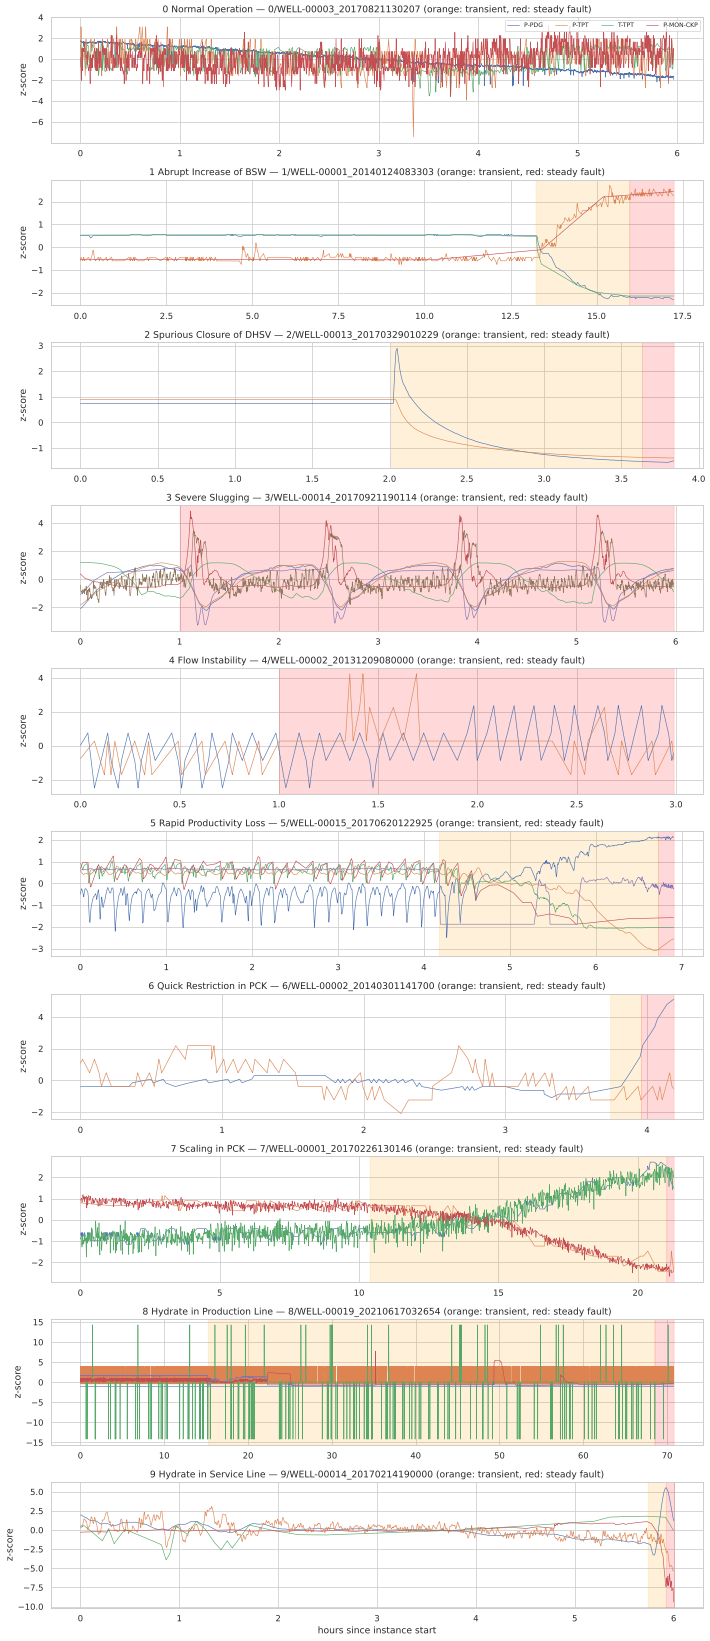

In [13]:
KEY = ["P-PDG", "P-TPT", "T-TPT", "P-MON-CKP", "T-JUS-CKP", "QGL"]

def pick(event_class: int) -> pd.Series:
    rows = real[real["event_class"] == event_class]
    with_t = rows[(rows["n_transient"] > 0) & (rows["n_steady"] > 0)]
    rows = with_t if len(with_t) else rows
    return rows.sort_values("duration_s").iloc[len(rows) // 2]

fig, axes = plt.subplots(10, 1, figsize=(13, 30))
for c, ax in zip(range(10), axes):
    meta = pick(c)
    df = load_instance(DATASET / meta["path"])
    t = (df.index - df.index[0]).total_seconds() / 3600
    for var in KEY:
        s = df[var]
        if s.notna().any() and s.std() > 0:
            ax.plot(t, (s - s.mean()) / s.std(), lw=0.8, label=var)
    labels = df["class"].astype("float")
    for mask, color in [(labels >= TRANSIENT_OFFSET, "orange"), ((labels >= 1) & (labels < TRANSIENT_OFFSET), "red")]:
        ax.fill_between(t, 0, 1, where=mask.to_numpy(dtype=bool), color=color, alpha=0.15,
                        transform=ax.get_xaxis_transform())
    ax.set_title(f"{c} {CLASS_NAMES[c]} — {meta['instance_id']} (orange: transient, red: steady fault)")
    ax.set_ylabel("z-score")
axes[0].legend(ncol=6, loc="upper right", fontsize=8)
axes[-1].set_xlabel("hours since instance start")
fig.tight_layout(); fig.savefig(FIGS / "eda_fault_signatures.png", dpi=60)

## 6. Class imbalance (rows of labelled data)

In [14]:
rows = profile.groupby(["event_class", "source"])[["n_normal", "n_transient", "n_steady"]].sum()
share = rows.groupby("source").transform(lambda x: x / x.sum()).round(3)
rows_real = rows.xs("real", level="source")
rows_real.assign(**{"share of real labelled rows": rows_real.sum(axis=1) / rows_real.values.sum()}).round(3)

,n_normal,n_transient,n_steady,share of real labelled rows
event_class,,,,
0,10019783,0,0,0.347
1,147271,65340,9783,0.008
2,87436,89091,21274,0.007
3,0,0,569152,0.020
4,0,0,2454883,0.085
5,65931,320672,13205,0.014
6,36023,6569,13285,0.002
7,1034424,6670582,30339,0.268
8,962297,3655418,140920,0.165


## 7. Decisions

These follow from the numbers above and are applied in Tasks 4 and 5.

1. **Variables: keep 7 core sensors** — `P-PDG, P-TPT, T-TPT, P-MON-CKP, T-JUS-CKP, P-JUS-CKGL, QGL`.
   The first five are present in every simulated and hand-drawn instance and in 50–92% of real
   ones; P-JUS-CKGL and QGL are present in 62% / 40% of real instances. Every other variable is
   either absent from all simulated/drawn data (P-ANULAR, T-PDG, ABER-*) or almost never present
   in real data (T-MON-CKP, P-JUS-CKP, P-JUS-BS, P-MON-SDV-P, P-MON-CKGL, QBS, PT-P). Valve
   states are dropped: they are absent from simulated/drawn data.
2. **Missing values: mask + fill.** Whole-variable absence is the norm (no instance has all 7),
   so each variable gets a binary `missing` channel. Short NaN runs inside a series are
   forward-filled (max 60 s); the rest is filled with the training mean after scaling (i.e. 0).
   There are **no timestamp gaps**: every file is a clean 1 Hz series, so no resampling is needed.
3. **Frozen (stuck) sensors are treated as missing.** P-PDG is constant over the whole instance in
   79% of the real instances where it is present (QGL 67%, T-PDG 59%), but never in simulated
   data. A rule that also works online: a value unchanged for ≥ 30 min is masked as missing.
4. **The first hour of every real instance is unlabelled** (exactly 3,600 rows, always a leading
   block). It is used as history for windows but never as a training target.
5. **Sources: train on real + simulated + drawn; validate and test on real only**, on held-out
   wells. Caveat: classes 3 and 6 come from only 2 real wells and classes 1 and 5 from 3, so a
   strict per-well split cannot put every class in every split; Task 5 must handle this
   explicitly and report which classes are covered.
6. **Shortcut risk.** Missingness differs by source (e.g. QGL is present in 40% of real but 14% of
   simulated instances), so a model could learn "this looks simulated" instead of the fault. The
   real-only test set guards against this; Task 7 adds an ablation without missing masks.
7. **Imbalance.** Of the real labelled rows, normal is 35%, class 7 27% and class 8 17%, while
   classes 1, 2 and 6 are each under 1%. Use macro F1 as the main metric, class-weighted losses,
   and cap windows per instance so multi-day instances (classes 7, 8) do not dominate.
8. **Label caveats.** Classes 3 and 4 have no transient label, so early warning is undefined for
   them (detection only). 43 of the 57 real class-9 instances contain only normal labels; with
   labels taken at the window end these simply become normal windows.
